* **Author:** Elyse Owen
* **Date:** 16 November 2026
* **Class Title:** EDS220: Working with Environmental Data

## TASK 2: Visualizing fire Scars through false color

**Github Repository Link:** 
https://github.com/eowen19/eds220-hwk4

---
## About
In early January of 2025, the Eaton and Palisades fires burned through portions of Los Angeles county, destroying many residences and leaving communities realing in the aftermath. This notebook looks at the fire perimeters of both fires, as well as a Landsat8 image captured on 23 February 2025. The fire perimeters, when combined with the Landsat8 image, show the burn scars of the two fires. The final map is produced as a false-colour composite to better highlight the burn scars in comparision to the surrounding vegetation. 


### Readings

- NASA EARTH OBSERVATORY: https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/
- WHAT ARE THE BANDS DESIGNATION: https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites
- COmmon LANDSAT BAND COMBOS: https://www.usgs.gov/media/images/common-landsat-band-combinations

### About the Data
This task will use two datasets:

**First dataset:Landsat Collection 2 Level-2 atmospherically:**
* Collection of bands (**red,green,blue,near-infrared and shortwave infared**)
  - `landsat8-2025-02-23-palisades-eaton.nc`
  
**Second dataset:Fire perimeters for the Eaton and Palisades fires:** 
- *More than one File*
  - `Eaton_Perimeter_20250121`
  - `Palisades_Perimieter_20250121`


## References
County of Los Angeles. (2025). _Palisades and Eaton Dissolved Fire Perimeters (2025)_[Dataset]. County of Los Angeles. https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about

Landsat Collection 2 Level-2. _Landsat 8_[Dataset]. Microsoft Planetary Computer. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2 

## 1. Import Libraries

In [1]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr   
import rioxarray as rioaxr

## 1b. Import data

In [2]:
# Import fire perimeters

palisades = gpd.read_file(os.path.join('data', 
                                    'Palisades_Perimieter_20250121', 
                                    'Palisades_Perimieter_20250121.shp'))


eaton = gpd.read_file(os.path.join('data', 
                                    'Eaton_Perimeter_20250121', 
                                    'Eaton_Perimeter_20250121.shp'))


## 2. Fire perimeter data exploration
---
Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.



In [3]:
# Print the CRSs of the Eaton and Palisades geodataframes
print('Eaton CRS:', eaton.crs)
print('Palisades CRS:', palisades.crs)

Eaton CRS: EPSG:4269
Palisades CRS: EPSG:4269


The two fire perimeters have the same CRS (EPSG: 4269), a geographic CRS

## 3. NetCDF data import and exploration
---
Import the Landsat data using `xr.open_dataset()`.

a. Explore the data and write a brief summary of the information you obtained from the preliminary exploration.

b. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [4]:
# Import Landsat8 data using `xr.open_dataset()`
fp = os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp)
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The landsat dataset variables include the red, green, blue, nir08, swir22 bands as float32 data types, as well as a spatial_ref band as an int64. The dimensions are (y: 1418, x: 2742). The coordinates are x (int64), y(int64), and time(datetime64)

## 4. Restoring geospatial information


a.Use rio.crs to print the CRS of this dataset. Is this a geospatial object?

In [5]:
# Use `rio.crs` to print the CRS of the Landsat dataset
print('Landsat CRS:', landsat.rio.crs)

Landsat CRS: None


This is not a geospatial object.

b.You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable spatial_ref. Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset.

In [6]:
# Use `spatial_ref.crs_wkt` to print the CRS of the Landsat dataset
landsat_crs = landsat.spatial_ref.crs_wkt
landsat_crs

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

c. Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.


In [7]:
# Use `rio.write_crs()` to recover the Landsat dataset CRS
landsat = landsat.rio.write_crs('EPSG:32611', inplace=True)

d.Print the CRS of the updated dataset.

In [8]:
# Print the updated Landsat dataset CRS
print('Landsat CRS:', landsat.rio.crs)

Landsat CRS: EPSG:32611


## 5. True color image

a. Without creating any new variables:
- select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data,
- convert it to an xarray.DataArray using the to_dataarray() method, and then
- use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.

In [9]:
# Select the red, green, and blue bands of the Landsat dataset. Convert to an xarray.Dataarray.
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


<Figure size 640x480 with 1 Axes>

b. Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.
To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

In [10]:
# Isolate NAs within the bands
bands = ['red','green','blue', 'nir08', 'swir22']

for band in bands:
    na_total = int(np.isnan(landsat[band]).sum())
    print(f"The {band} band has {na_total} NA values.")

The red band has 0 NA values.
The green band has 1 NA values.
The blue band has 109 NA values.
The nir08 band has 0 NA values.
The swir22 band has 0 NA values.


c. Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.


In [11]:
# Replace NA values with zeros
landsat = landsat.fillna(value= 0)

d. Create a new true color image that gets plotted without warnings.


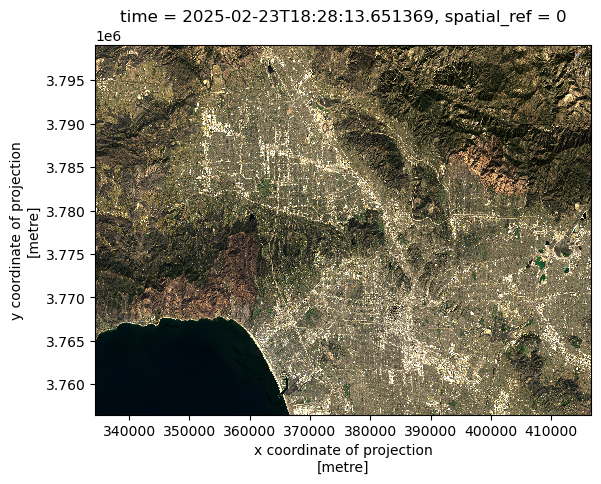

In [12]:
# Reprint the true colour image without warnings
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

e. In a markdown cell write a brief explanation comparing the outputs for parts (a) and (d).

In section A, the image that is produced is blank and contains warning messages regarding the NAN values. In section D, the NAN values have been set to 0, and the robust parameter has been set to true. Setting the NAN values to 0 has removed the warnings, while setting the robust parameter to true has produced a true colour image that is reasonable.

## 6. False color image
Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order).

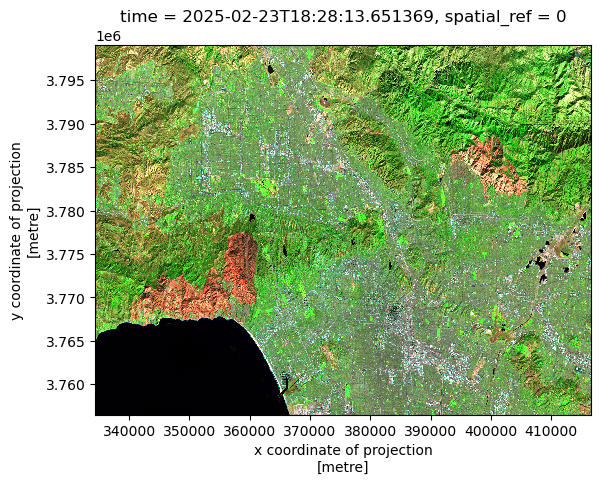

In [13]:
# Select the short-wave infrared, near-infrared, and red bands of the Landsat dataset. Convert to an xarray.Dataarray.
landsat[["swir22", "nir08", "red"]].to_dataarray().plot.imshow(robust=True)
plt.show()

## 7. Map
---

a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

In [14]:
# Print the CRSs of the Eaton, Palisades geodataframes and the Landsat dataarray
print('Eaton CRS:', eaton.crs)
print('Palisades CRS:', palisades.crs)
print('Landsat CRS:', landsat.rio.crs)


Eaton CRS: EPSG:4269
Palisades CRS: EPSG:4269
Landsat CRS: EPSG:32611


In [15]:
# Match Eaton, Palisades CRSs to Landsat CRS
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

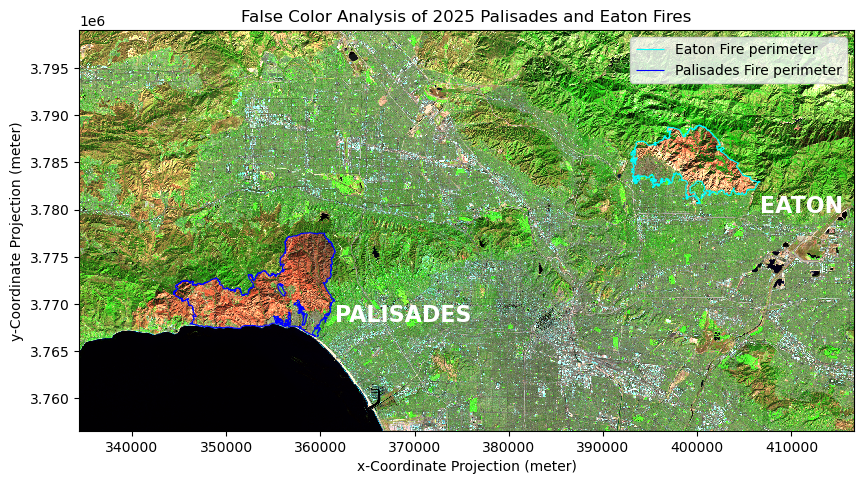

In [16]:

#Finding max coordinates of fire polygons
eaton_max = eaton.geometry.get_coordinates().max()
palisades_max = palisades.geometry.get_coordinates().max()


#Max coords
max_x = [eaton_max.iloc[0], palisades_max.iloc[0]]
max_y = [eaton_max.iloc[1], palisades_max.iloc[1]]

#Create map to combine landsat data and fire perimeters
fig, ax = plt.subplots(figsize=(10,8))

#Plot false color composite
landsat[['swir22','nir08','red']].to_dataarray().plot.imshow(ax = ax, robust=True)

#Overlay Palisades and Eaton fire perimeters
eaton.boundary.plot(ax=ax, edgecolor='aqua', linewidth=0.8, label='Eaton Fire perimeter')
palisades.boundary.plot(ax=ax, edgecolor='blue', linewidth=0.8, label='Palisades Fire perimeter')

#Add title, x/y axes labels, and legend
ax.set_title('False Color Analysis of 2025 Palisades and Eaton Fires')
plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.legend()

#Add fire name annotations
combined_fires = pd.concat([eaton, palisades])
for x, y, name in zip(max_x, max_y, combined_fires['FIRE_NAME']):
    ax.text(x,y-7500,name, fontsize=16, ha='left', va = 'top', color= 'white', fontweight='bold')

plt.show()

b. Write a figure description for the map including a brief explanation of how false color imagery is being used.

The map shows the fire perimeters of the Eaton and Palisades fires that burned in early 2025. The Landsat image that the map is built upon is from 23 February 2025, after both fires had burned completely. As such, the burn areas can be clearly seen within the two fire perimeters, contrasting in the false-colour composite. A false-colour composite has been used as it much more clearly shows the difference in burnt versus non-burnt vegetation areas. 

##